In [1]:
!git clone --depth 1 https://github.com/tamu-datathon-org/dashboard-royale.git
%cd dashboard-royale

Cloning into 'dashboard-royale'...
remote: Enumerating objects: 88, done.
remote: Counting objects: 100% (88/88), done.
remote: Compressing objects: 100% (87/87), done.
remote: Total 88 (delta 1), reused 84 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (88/88), 243.79 MiB | 23.22 MiB/s, done.
Resolving deltas: 100% (1/1), done.
Updating files: 100% (76/76), done.
/content/dashboard-royale


In [2]:
!sudo apt-get update && sudo apt-get install -y python3-venv
!python -m venv .venv --without-pip

Get:1 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Get:2 https://cli.github.com/packages stable InRelease [3,917 B]
Hit:3 http://archive.ubuntu.com/ubuntu noble InRelease
Get:4 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Get:5 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Get:6 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:7 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ Packages [79.0 kB]
Get:8 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease [17.8 kB]
Get:9 http://archive.ubuntu.com/ubuntu noble-backports InRelease [126 kB]
Get:10 https://cli.github.com/packages stable/main amd64 Packages [357 B]
Get:11 https://r2u.stat.illinois.edu/ubuntu noble/main all Packages [10.5 MB]
Get:12 http://archive.ubuntu.com/ubuntu noble-updates/multiverse amd64 Packages [61.8 kB]
Get:13 http://archive.ubuntu.com/ubuntu noble-updates/universe amd64 Packages [2,177 kB]
Get:

In [3]:
!python -m pip install pandas pyarrow


In [4]:
import pandas as pd

import pandas as pd

# Load the daily machine view (56,110 rows × 44 columns)
daily = pd.read_parquet("data/1_prepared_views/prepared_daily_view.parquet")
print(daily.head())

# Load the property-level daily summary
property_day = pd.read_parquet("data/1_prepared_views/property_day.parquet")

# Load the player period view
player_period = pd.read_parquet("data/1_prepared_views/player_period.parquet")

  machine_id gaming_date    month local_weekday  is_weekend federal_holiday  \
0     M-1001  2025-01-01  2025-01           Wed       False  New Year's Day   
1     M-1001  2025-01-02  2025-01           Thu       False            None   
2     M-1001  2025-01-03  2025-01           Fri       False            None   
3     M-1001  2025-01-04  2025-01           Sat        True            None   
4     M-1001  2025-01-05  2025-01           Sun        True            None   

  events_active zone_id      zone_name bank_id  ... zone_entries_observed  \
0          None   Z-ENT  Main Entrance    B-01  ...                1999.0   
1          None   Z-ENT  Main Entrance    B-01  ...                2530.0   
2          None   Z-ENT  Main Entrance    B-01  ...                3145.0   
3          None   Z-ENT  Main Entrance    B-01  ...                3560.0   
4          None   Z-ENT  Main Entrance    B-01  ...                2865.0   

  zone_counter_coverage_hours lease_cost_usd service_cost_usd 

In [5]:
!python -m pip install duckdb

In [6]:
import duckdb

duckdb.sql("""
    SELECT machine_id,
           SUM(house_win_usd)                    AS house_win,
           SUM(theo_usd)                         AS expected_win,
           SUM(house_win_usd) / NULLIF(SUM(coin_in_usd), 0) AS observed_hold,
           SUM(available_hours) /
               (SUM(c.scheduled_seconds) / 3600.0) AS availability
    FROM 'data/1_prepared_views/prepared_daily_view.parquet' AS d
    JOIN 'data/2_machine_decision/calendar_day.parquet' AS c
      USING (gaming_date)
    WHERE d.active
    GROUP BY machine_id
    ORDER BY house_win
    LIMIT 10
""").show()

┌────────────┬───────────────┬───────────────┬──────────────────────┬────────────────────┐
│ machine_id │   house_win   │ expected_win  │    observed_hold     │    availability    │
│  varchar   │ decimal(38,2) │ decimal(38,4) │        double        │       double       │
├────────────┼───────────────┼───────────────┼──────────────────────┼────────────────────┤
│ M-5076     │       3573.25 │     7478.7000 │  0.02388951288325511 │ 0.9948979591836735 │
│ M-1158     │      15796.25 │    51961.0000 │ 0.030400203999153212 │ 0.9993058433750351 │
│ M-1120     │      16355.00 │    18910.9250 │  0.04324219994526973 │ 0.9946838052134863 │
│ M-1118     │      20050.00 │    25329.0000 │  0.07915827707370998 │ 0.9950481902356902 │
│ M-1238     │      24932.75 │    33139.3125 │  0.03761808577048784 │   0.99742196894108 │
│ M-1181     │      26977.00 │    32516.1600 │  0.06637192091563088 │ 0.9978396909458387 │
│ M-1035     │      30303.50 │    30894.6000 │  0.04904336032834217 │ 0.9991679458643539 │

is the bottom 10 list correct?

In [7]:
%load_ext rpy2.ipython

In [8]:
# Install pre-compiled R binary for arrow via system package manager
!sudo apt-get update && sudo apt-get install -y r-cran-arrow

Hit:1 https://cli.github.com/packages stable InRelease
Hit:2 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease
Hit:3 http://security.ubuntu.com/ubuntu noble-security InRelease
Hit:4 https://r2u.stat.illinois.edu/ubuntu noble InRelease
Hit:5 http://archive.ubuntu.com/ubuntu noble InRelease
Hit:6 http://archive.ubuntu.com/ubuntu noble-updates InRelease
Hit:7 http://archive.ubuntu.com/ubuntu noble-backports InRelease
Hit:8 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease
Reading package lists... Done
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  r-cran-assertthat
Suggested packages:
  r-cran-decor r-cran-distro r-cran-duckdb r-cran-reticulate r-cran-covr
The 

In [9]:
%%R
# Load the arrow library directly
library(arrow)

# Read the parquet dataset
daily <- read_parquet("data/1_prepared_views/prepared_daily_view.parquet")
head(daily)

property_day <- read_parquet("data/1_prepared_views/property_day.parquet")
player_period <- read_parquet("data/1_prepared_views/player_period.parquet")


Attaching package: ‘arrow’

The following object is masked from ‘package:utils’:

    timestamp



In [10]:
# Python
daily.to_csv("prepared_daily_view.csv", index=False)
property_day.to_csv("property_day.csv", index=False)
player_period.to_csv("player_period.csv", index=False)

Q2. demand changes

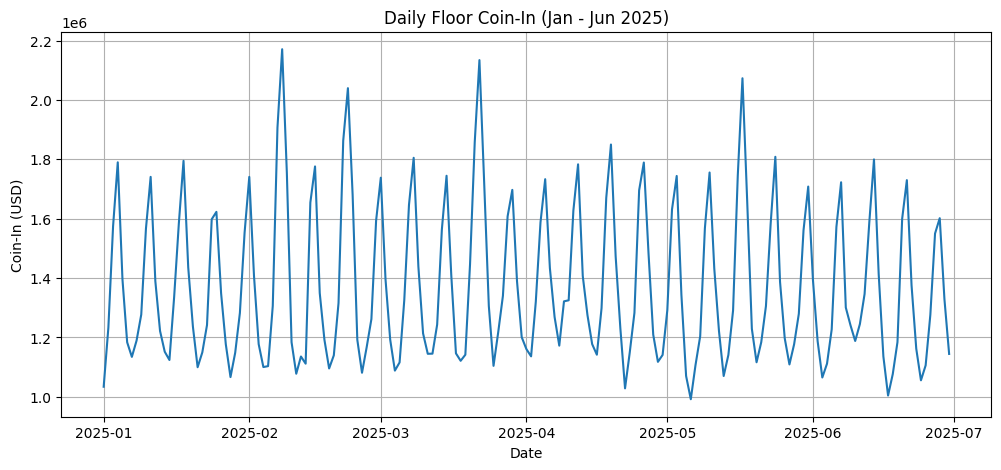

Average Coin-In by Day of Week:
weekday
Monday       1199784.355769
Tuesday         1100766.814
Wednesday    1147935.411538
Thursday     1282761.921154
Friday       1636246.582692
Saturday     1803585.940385
Sunday       1444533.823077
Name: coin_in_usd, dtype: object


In [31]:
import pandas as pd
import matplotlib.pyplot as plt

# Load property-level daily summary
property_day = pd.read_parquet("data/1_prepared_views/property_day.parquet")

# Convert gaming_date to datetime
property_day['gaming_date'] = pd.to_datetime(property_day['gaming_date'])

# 1. Plot daily total coin-in over time
plt.figure(figsize=(12, 5))
plt.plot(property_day['gaming_date'], property_day['coin_in_usd'], label='Daily Coin-In ($)')
plt.title('Daily Floor Coin-In (Jan - Jun 2025)')
plt.xlabel('Date')
plt.ylabel('Coin-In (USD)')
plt.grid(True)
plt.show()

# 2. Compare Day of Week trends
property_day['weekday'] = property_day['gaming_date'].dt.day_name()
weekday_avg = property_day.groupby('weekday')['coin_in_usd'].mean().reindex([
    'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'
])
print("Average Coin-In by Day of Week:")
print(weekday_avg)

In [12]:
# Load events data
events = pd.read_parquet("data/4_context/events.parquet")

# Inspect the actual columns available in the dataset
print("Available columns:", events.columns.tolist())

# Let's print the correct columns that exist in the DataFrame (e.g., 'name', 'event_type')
existing_cols = [col for col in ['name', 'event_id', 'event_type'] if col in events.columns]
print(events[existing_cols])

Available columns: ['event_id', 'name', 'event_type', 'start_date', 'end_date', 'announced_date', 'source_type', 'source_url', 'local_scope']
                                           name     event_id  \
0                                           CES     EV-CES25   
1                        Super Bowl LIX weekend      EV-SB59   
2  College basketball tournament opening rounds      EV-MM25   
3                                     CinemaCon      EV-CC25   
4                                      NAB Show     EV-NAB25   
5                EDC Las Vegas festival weekend     EV-EDC25   
6             Gilded Ace Winter Slot Tournament   EV-P-TOURN   
7           Gilded Ace Locals Appreciation Week  EV-P-LOCALS   

           event_type  
0          convention  
1      sports_viewing  
2      sports_viewing  
3          convention  
4          convention  
5            festival  
6  property_promotion  
7  property_promotion  


In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Ensure data is loaded
property_day = pd.read_parquet("data/1_prepared_views/property_day.parquet")
events = pd.read_parquet("data/4_context/events.parquet")

# Convert dates to datetime objects
property_day['gaming_date'] = pd.to_datetime(property_day['gaming_date'])
events['start_date'] = pd.to_datetime(events['start_date'])
events['end_date'] = pd.to_datetime(events['end_date'])

# Create a mapping of dates to events
date_event_map = {}
for _, row in events.iterrows():
    # Generate a range of dates for which the event is active
    event_dates = pd.date_range(start=row['start_date'], end=row['end_date'])
    for dt in event_dates:
        if dt not in date_event_map:
            date_event_map[dt] = []
        date_event_map[dt].append(row['name'])

# Map active events to each day in property_day
property_day['active_events_list'] = property_day['gaming_date'].map(date_event_map)
property_day['has_event'] = property_day['active_events_list'].notna() & property_day['active_events_list'].apply(lambda x: len(x) > 0 if isinstance(x, list) else False)
property_day['event_names'] = property_day['active_events_list'].apply(lambda x: ", ".join(x) if isinstance(x, list) else "None")

# Display days with active events and coin-in to verify
display(property_day[property_day['has_event']][['gaming_date', 'coin_in_usd', 'event_names']].head(10))

,gaming_date,coin_in_usd,event_names
6,2025-01-07,1134379.05,CES
7,2025-01-08,1189128.20,CES
8,2025-01-09,1276893.65,CES
9,2025-01-10,1566483.50,CES
37,2025-02-07,1906781.20,Super Bowl LIX weekend
38,2025-02-08,2170909.05,Super Bowl LIX weekend
39,2025-02-09,1753638.80,Super Bowl LIX weekend
51,2025-02-21,1862730.55,Gilded Ace Winter Slot Tournament
52,2025-02-22,2039692.00,Gilded Ace Winter Slot Tournament
53,2025-02-23,1681518.60,Gilded Ace Winter Slot Tournament


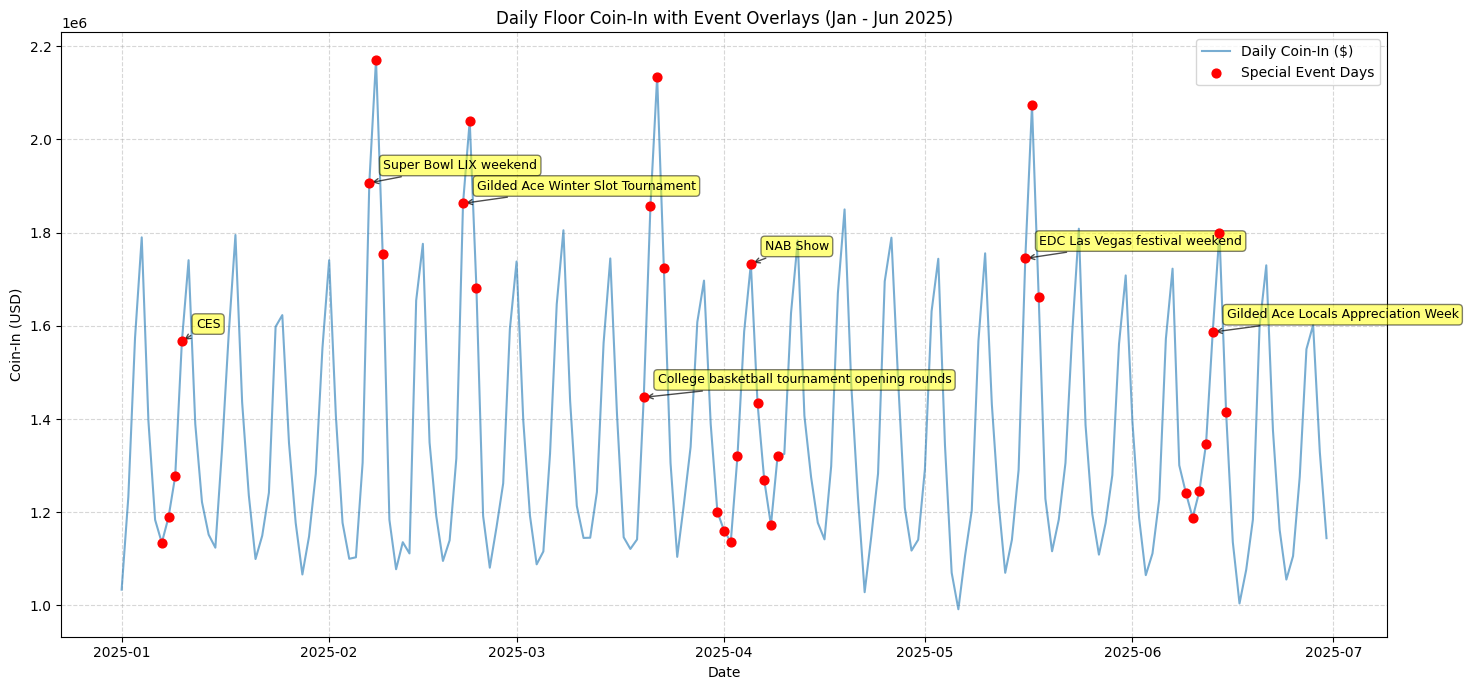

In [14]:
# Plot daily total coin-in over time, highlighting active events
plt.figure(figsize=(15, 7))

# Line plot for overall daily trends
plt.plot(property_day['gaming_date'], property_day['coin_in_usd'], color='#1f77b4', alpha=0.6, label='Daily Coin-In ($)')

# Highlight dates with events
event_days = property_day[property_day['has_event']]
plt.scatter(event_days['gaming_date'], event_days['coin_in_usd'], color='red', s=40, zorder=5, label='Special Event Days')

# Annotate key events with spikes
annotations_made = set()
for _, row in event_days.iterrows():
    # Only annotate the most significant events or peaks to avoid cluttering
    event_lbl = row['event_names']
    if event_lbl not in annotations_made and row['coin_in_usd'] > property_day['coin_in_usd'].mean():
        plt.annotate(event_lbl,
                     xy=(row['gaming_date'], row['coin_in_usd']),
                     xytext=(10, 10),
                     textcoords='offset points',
                     arrowprops=dict(arrowstyle="->", color='black', alpha=0.7),
                     fontsize=9,
                     bbox=dict(boxstyle="round,pad=0.3", fc="yellow", alpha=0.5))
        annotations_made.add(event_lbl)

plt.title('Daily Floor Coin-In with Event Overlays (Jan - Jun 2025)')
plt.xlabel('Date')
plt.ylabel('Coin-In (USD)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Traffic Counter Status counts:
counter_status
ok         30150
offline      153
partial       98
Name: count, dtype: int64


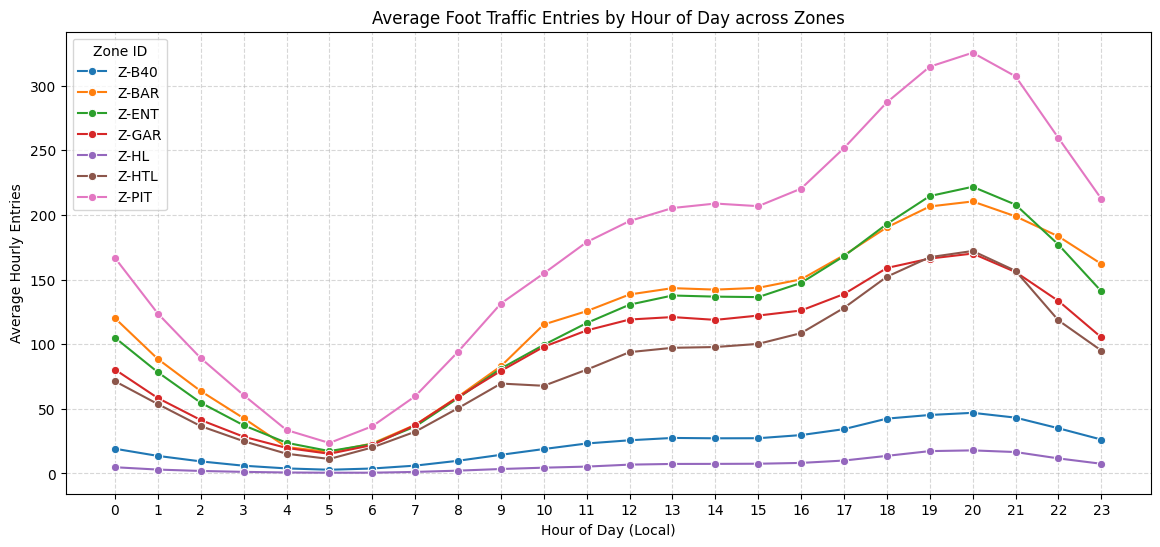

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load hourly traffic counts
traffic = pd.read_parquet("data/4_context/zone_traffic_hourly.parquet")

# Check available statuses first
print("Traffic Counter Status counts:")
print(traffic['counter_status'].value_counts(dropna=False))

# Filter for operational counters. If 'OK' is not there, we'll keep non-null or active statuses
if 'OK' in traffic['counter_status'].unique():
    valid_traffic = traffic[traffic['counter_status'] == 'OK'].copy()
else:
    # Fallback to taking everything if the status has different codes, or keep non-nulls
    valid_traffic = traffic[traffic['counter_status'].notna()].copy()

# Parse timestamps
valid_traffic['hour_start_local'] = pd.to_datetime(valid_traffic['hour_start_local'])
valid_traffic['date'] = valid_traffic['hour_start_local'].dt.date

# 1. Peak Hours Analysis
hourly_zone_traffic = valid_traffic.groupby(['zone_id', 'local_hour'])['entries_count'].mean().reset_index()

plt.figure(figsize=(14, 6))
sns.lineplot(data=hourly_zone_traffic, x='local_hour', y='entries_count', hue='zone_id', marker='o')
plt.title('Average Foot Traffic Entries by Hour of Day across Zones')
plt.xlabel('Hour of Day (Local)')
plt.ylabel('Average Hourly Entries')
plt.grid(True, linestyle='--', alpha=0.5)
plt.xticks(range(0, 24))
plt.legend(title='Zone ID')
plt.show()

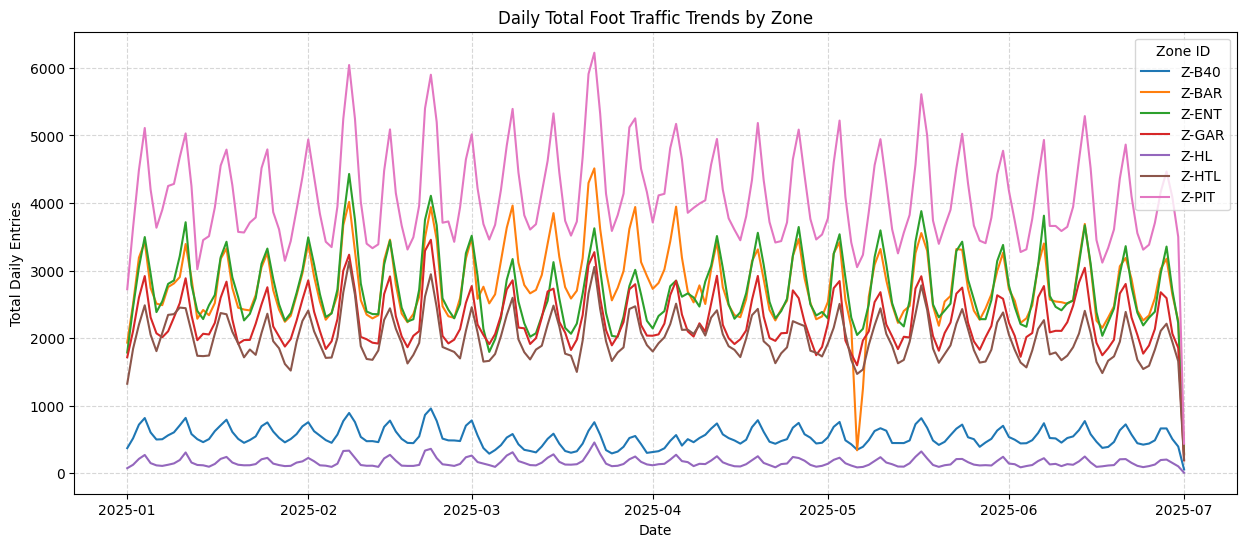

In [16]:
# 2. Daily Traffic Trends Over Time
daily_zone_traffic = valid_traffic.groupby(['zone_id', 'date'])['entries_count'].sum().reset_index()
daily_zone_traffic['date'] = pd.to_datetime(daily_zone_traffic['date'])

plt.figure(figsize=(15, 6))
sns.lineplot(data=daily_zone_traffic, x='date', y='entries_count', hue='zone_id')
plt.title('Daily Total Foot Traffic Trends by Zone')
plt.xlabel('Date')
plt.ylabel('Total Daily Entries')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Zone ID')
plt.show()

Columns in property_day: ['gaming_date', 'local_weekday', 'events_active', 'active_machines', 'coin_in_usd', 'payout_usd', 'house_win_usd', 'theo_usd', 'observed_hold', 'available_machine_hours', 'occupied_machine_hours', 'carded_coin_in_share', 'pos_cash_usd', 'pos_cogs_usd', 'comp_face_value_usd', 'comp_cost_usd', 'faults_opened', 'incidents_reported', 'entrance_zone_entries_observed', 'total_zone_entries_observed', 'counter_coverage_share', 'machine_supplied_costs_usd', 'tech_labor_cost_usd', 'contribution_after_supplied_costs_usd']

Using matching columns for correlation: ['coin_in_usd', 'payout_usd', 'house_win_usd', 'theo_usd', 'active_machines', 'comp_cost_usd']

--- Pearson Correlation with Coin-In ---
coin_in_usd        1.000000
theo_usd           0.999799
payout_usd         0.998967
house_win_usd      0.919827
comp_cost_usd      0.870759
active_machines   -0.054224
Name: coin_in_usd, dtype: float64


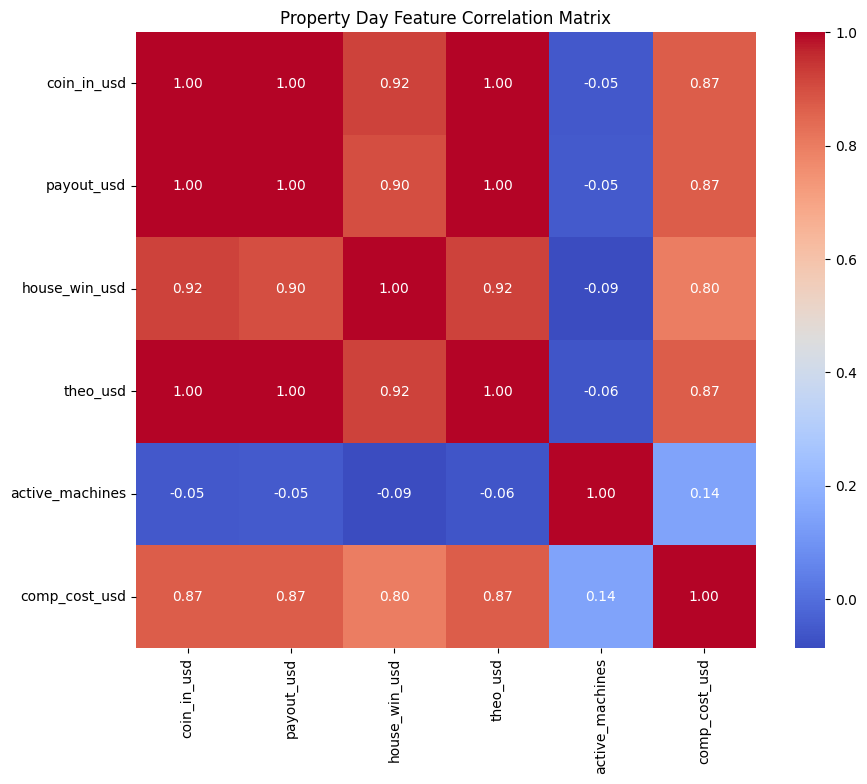

In [17]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Load property_day summary
df = pd.read_parquet("data/1_prepared_views/property_day.parquet")

# Let's inspect the actual columns to avoid any future KeyErrors
print("Columns in property_day:", df.columns.tolist())

# 2. Select potential driver features that actually exist in the DataFrame
candidate_features = [
    'coin_in_usd',
    'payout_usd',
    'house_win_usd',
    'theo_usd',
    'active_machines',
    'carded_coin_in_usd',  # Let's see if this one or others are named slightly differently
    'fnb_gross_usd',
    'fnb_transactions',
    'comp_cost_usd',
    'fault_count'
]

# Keep only the columns that are present in the dataframe
existing_candidates = [col for col in candidate_features if col in df.columns]
print("\nUsing matching columns for correlation:", existing_candidates)

# Drop missing values for selected features
df_clean = df[existing_candidates].dropna()

# 3. Calculate Pearson Correlation with coin_in_usd
if 'coin_in_usd' in df_clean.columns and len(df_clean.columns) > 1:
    correlations = df_clean.corr()['coin_in_usd'].sort_values(ascending=False)
    print("\n--- Pearson Correlation with Coin-In ---")
    print(correlations)

    # Plot Correlation Heatmap
    plt.figure(figsize=(10, 8))
    sns.heatmap(df_clean.corr(), annot=True, cmap='coolwarm', fmt=".2f")
    plt.title("Property Day Feature Correlation Matrix")
    plt.show()
else:
    print("Could not compute correlation matrix: Missing required columns.")

In [18]:
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import StandardScaler

# 1. Separate target (coin_in_usd) and predictor features (X)
X = df_clean.drop(columns=['coin_in_usd'])
y = df_clean['coin_in_usd']

# 2. Standardize features (SVD requires zero mean and unit variance)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Apply SVD (e.g., 2 components)
svd = TruncatedSVD(n_components=2, random_state=42)
X_svd = svd.fit_transform(X_scaled)

# 4. View Explained Variance
print(f"Explained Variance Ratio by Component: {svd.explained_variance_ratio_}")
print(f"Total Variance Explained by Top 2 SVD Components: {svd.explained_variance_ratio_.sum():.2%}")

# 5. Inspect Feature Loadings for each Component
loadings = pd.DataFrame(
    svd.components_.T,
    index=X.columns,
    columns=['SVD_Component_1', 'SVD_Component_2']
)
print("\n--- SVD Feature Loadings ---")
print(loadings)

Explained Variance Ratio by Component: [0.7364342  0.20803809]
Total Variance Explained by Top 2 SVD Components: 94.45%

--- SVD Feature Loadings ---
                 SVD_Component_1  SVD_Component_2
payout_usd              0.512762        -0.032373
house_win_usd           0.491802        -0.081722
theo_usd                0.515318        -0.045847
active_machines        -0.011700         0.976433
comp_cost_usd           0.479078         0.191703



--- SVD Component Correlation to Coin-In ---
Component_1    0.988909
Component_2   -0.038598
coin_in_usd    1.000000
Name: coin_in_usd, dtype: float64


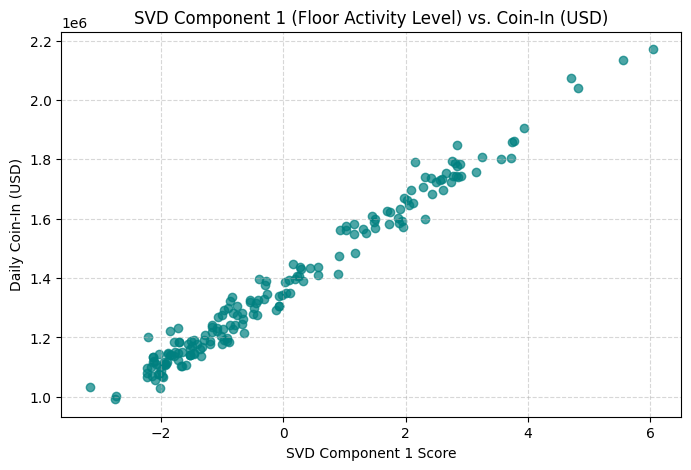

In [19]:
# Combine SVD components with target variable
svd_df = pd.DataFrame(X_svd, columns=['Component_1', 'Component_2'])
svd_df['coin_in_usd'] = y.values

# Compute correlations
print("\n--- SVD Component Correlation to Coin-In ---")
print(svd_df.corr()['coin_in_usd'])

# Scatter plot: Component 1 vs Coin-In
plt.figure(figsize=(8, 5))
plt.scatter(svd_df['Component_1'], svd_df['coin_in_usd'], alpha=0.7, color='teal')
plt.title('SVD Component 1 (Floor Activity Level) vs. Coin-In (USD)')
plt.xlabel('SVD Component 1 Score')
plt.ylabel('Daily Coin-In (USD)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

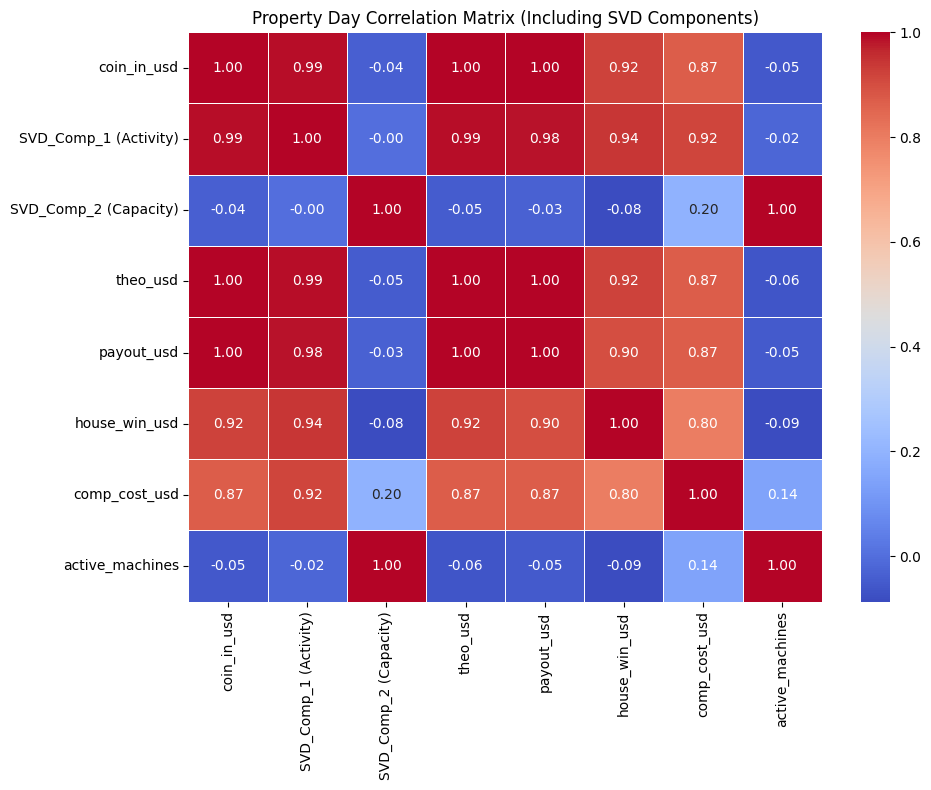

In [20]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import StandardScaler

# 1. Load property_day summary
df = pd.read_parquet("data/1_prepared_views/property_day.parquet")

# 2. Select numerical features present in the dataset
candidate_features = [
    'coin_in_usd',
    'payout_usd',
    'house_win_usd',
    'theo_usd',
    'active_machines',
    'comp_cost_usd'
]
df_clean = df[candidate_features].dropna()

# 3. Fit TruncatedSVD on predictor features
X = df_clean.drop(columns=['coin_in_usd'])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

svd = TruncatedSVD(n_components=2, random_state=42)
X_svd = svd.fit_transform(X_scaled)

# 4. Construct DataFrame containing raw features + SVD components
corr_df = df_clean.copy()
corr_df['SVD_Comp_1 (Activity)'] = X_svd[:, 0]
corr_df['SVD_Comp_2 (Capacity)'] = X_svd[:, 1]

# Reorder columns so Coin-In and SVD components appear first
cols_order = ['coin_in_usd', 'SVD_Comp_1 (Activity)', 'SVD_Comp_2 (Capacity)',
              'theo_usd', 'payout_usd', 'house_win_usd', 'comp_cost_usd', 'active_machines']
corr_df = corr_df[cols_order]

# 5. Plot Correlation Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_df.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Property Day Correlation Matrix (Including SVD Components)")
plt.tight_layout()
plt.show()

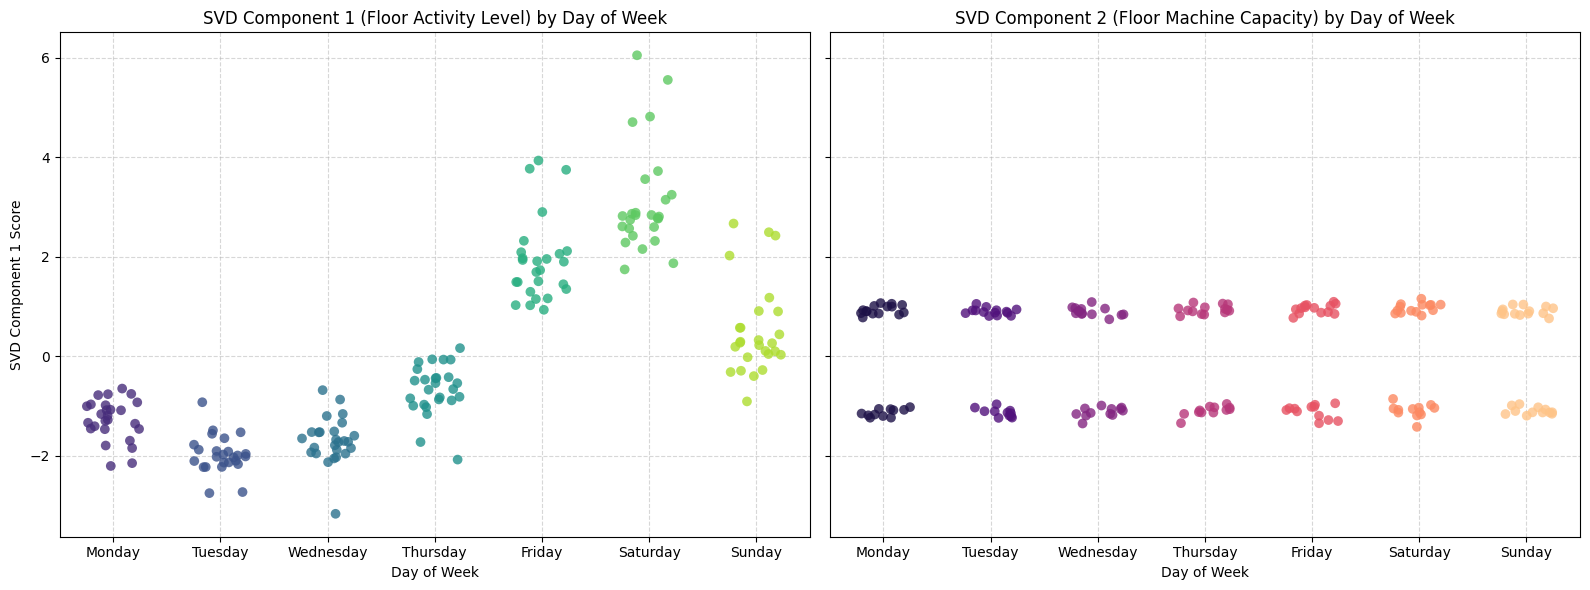

In [21]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import StandardScaler

# 1. Load property_day summary
df = pd.read_parquet("data/1_prepared_views/property_day.parquet")
df['gaming_date'] = pd.to_datetime(df['gaming_date'])

# Preserve day of week order
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
df['weekday'] = df['gaming_date'].dt.day_name()
df['weekday'] = pd.Categorical(df['weekday'], categories=weekday_order, ordered=True)

# 2. Extract SVD components
candidate_features = ['coin_in_usd', 'payout_usd', 'house_win_usd', 'theo_usd', 'active_machines', 'comp_cost_usd']
df_clean = df[candidate_features].dropna()

X = df_clean.drop(columns=['coin_in_usd'])
X_scaled = StandardScaler().fit_transform(X)

svd = TruncatedSVD(n_components=2, random_state=42)
X_svd = svd.fit_transform(X_scaled)

df.loc[df_clean.index, 'SVD_Comp_1'] = X_svd[:, 0]
df.loc[df_clean.index, 'SVD_Comp_2'] = X_svd[:, 1]

# 3. Create Side-by-Side Dot Plots (Strip Plots)
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

# Dot plot for SVD Component 1 (Activity Level)
sns.stripplot(
    data=df, x='weekday', y='SVD_Comp_1', hue='weekday',
    palette='viridis', jitter=0.25, size=7, alpha=0.8, ax=axes[0], legend=False
)
axes[0].set_title('SVD Component 1 (Floor Activity Level) by Day of Week')
axes[0].set_xlabel('Day of Week')
axes[0].set_ylabel('SVD Component 1 Score')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Dot plot for SVD Component 2 (Capacity Level)
sns.stripplot(
    data=df, x='weekday', y='SVD_Comp_2', hue='weekday',
    palette='magma', jitter=0.25, size=7, alpha=0.8, ax=axes[1], legend=False
)
axes[1].set_title('SVD Component 2 (Floor Machine Capacity) by Day of Week')
axes[1].set_xlabel('Day of Week')
axes[1].set_ylabel('SVD Component 2 Score')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

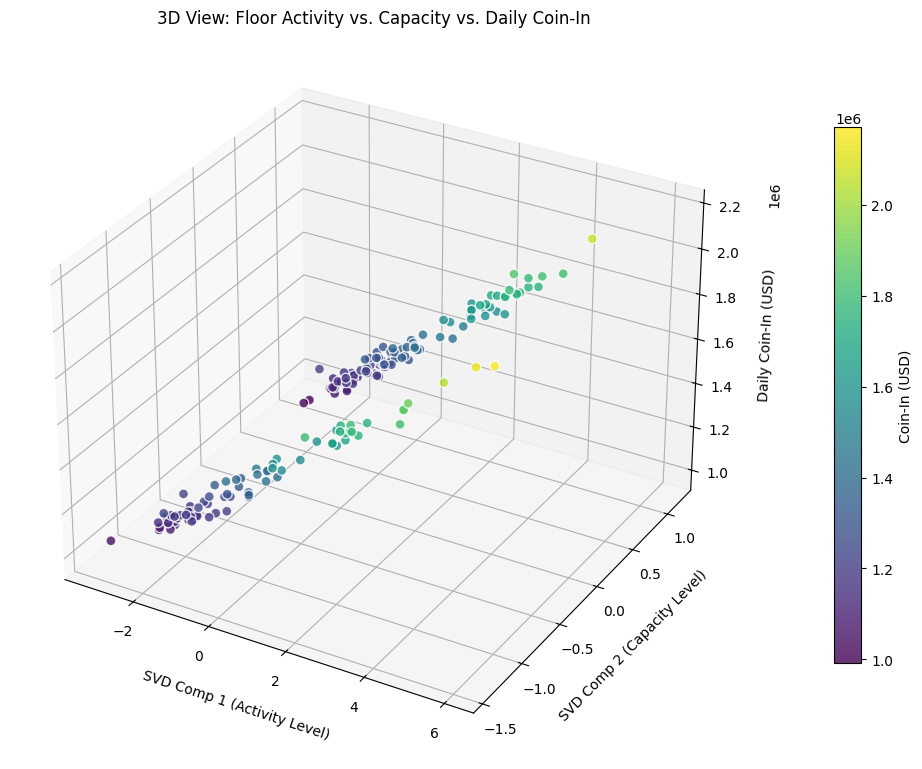

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import StandardScaler

# 1. Load property_day summary
df = pd.read_parquet("data/1_prepared_views/property_day.parquet")
df['gaming_date'] = pd.to_datetime(df['gaming_date'])

# Convert Decimal fields to standard floats to prevent plotting/math type conflicts
if 'coin_in_usd' in df.columns:
    df['coin_in_usd'] = df['coin_in_usd'].astype(float)

# 2. Extract SVD components
candidate_features = ['coin_in_usd', 'payout_usd', 'house_win_usd', 'theo_usd', 'active_machines', 'comp_cost_usd']
# Ensure all numeric candidates are cast to float to prevent SVD or Scaling type mismatches
for col in candidate_features:
    if col in df.columns:
        df[col] = df[col].astype(float)

df_clean = df[candidate_features].dropna()

X = df_clean.drop(columns=['coin_in_usd'])
X_scaled = StandardScaler().fit_transform(X)

svd = TruncatedSVD(n_components=2, random_state=42)
X_svd = svd.fit_transform(X_scaled)

comp_1 = X_svd[:, 0]
comp_2 = X_svd[:, 1]
coin_in = df_clean['coin_in_usd'].values

# 3. Create 3D Scatter Plot
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Scatter points colored by Coin-In volume
scatter = ax.scatter(
    comp_1,
    comp_2,
    coin_in,
    c=coin_in,
    cmap='viridis',
    s=50,
    alpha=0.8,
    edgecolors='w'
)

# Axis labels
ax.set_xlabel('SVD Comp 1 (Activity Level)', labelpad=10)
ax.set_ylabel('SVD Comp 2 (Capacity Level)', labelpad=10)
ax.set_zlabel('Daily Coin-In (USD)', labelpad=10)
ax.set_title('3D View: Floor Activity vs. Capacity vs. Daily Coin-In')

# Colorbar for coin-in values
cbar = fig.colorbar(scatter, ax=ax, pad=0.1, shrink=0.7)
cbar.set_label('Coin-In (USD)')

plt.tight_layout()
plt.show()

In [23]:
import plotly.express as px

# Create DataFrame for Plotly
plotly_df = pd.DataFrame({
    'SVD_Comp_1': comp_1,
    'SVD_Comp_2': comp_2,
    'Coin_In_USD': coin_in,
    'Date': df.loc[df_clean.index, 'gaming_date'].dt.strftime('%Y-%m-%d')
})

fig = px.scatter_3d(
    plotly_df,
    x='SVD_Comp_1',
    y='SVD_Comp_2',
    z='Coin_In_USD',
    color='Coin_In_USD',
    hover_data=['Date'],
    title='Interactive 3D Demand Drivers (SVD Components vs. Coin-In)',
    labels={
        'SVD_Comp_1': 'Activity Level (SVD 1)',
        'SVD_Comp_2': 'Machine Capacity (SVD 2)',
        'Coin_In_USD': 'Daily Coin-In ($)'
    }
)

fig.update_layout(margin=dict(l=0, r=0, b=0, t=40))
fig.show()

Floor demand (coin_in_usd) is driven almost entirely by macro activity factors (weekend foot traffic, events, and player loyalty activity), which explain 73.6% of property variance. Machine availability on the floor explains 20.8% of floor variance but has virtually zero impact ($r = -0.04$) on total daily wagers.Therefore, resolving underperformance should focus on optimizing machine placement and zone traffic flow rather than simply adding or removing machine capacity.

In [24]:
#go deeper with section
events = pd.read_parquet("data/4_context/events.parquet")
print(events[['name', 'event_type', 'start_date', 'end_date']])

                                           name          event_type  \
0                                           CES          convention   
1                        Super Bowl LIX weekend      sports_viewing   
2  College basketball tournament opening rounds      sports_viewing   
3                                     CinemaCon          convention   
4                                      NAB Show          convention   
5                EDC Las Vegas festival weekend            festival   
6             Gilded Ace Winter Slot Tournament  property_promotion   
7           Gilded Ace Locals Appreciation Week  property_promotion   

   start_date    end_date  
0  2025-01-07  2025-01-10  
1  2025-02-07  2025-02-09  
2  2025-03-20  2025-03-23  
3  2025-03-31  2025-04-03  
4  2025-04-05  2025-04-09  
5  2025-05-16  2025-05-18  
6  2025-02-21  2025-02-23  
7  2025-06-09  2025-06-15  


In [25]:
traffic = pd.read_parquet("data/4_context/zone_traffic_hourly.parquet")
valid_traffic = traffic[traffic['counter_status'] == 'ok']

# Group by zone and local hour to see foot traffic heatmaps
traffic_by_zone = valid_traffic.groupby(['zone_id', 'local_hour'])['entries_count'].mean().unstack()

In [26]:
import pandas as pd

# Load property totals and events context
property_day = pd.read_parquet("data/1_prepared_views/property_day.parquet")
events = pd.read_parquet("data/4_context/events.parquet")

# Convert date columns
property_day['gaming_date'] = pd.to_datetime(property_day['gaming_date'])
events['start_date'] = pd.to_datetime(events['start_date'])
events['end_date'] = pd.to_datetime(events['end_date'])

# Map active events to each day
date_event_map = {}
for _, row in events.iterrows():
    for dt in pd.date_range(start=row['start_date'], end=row['end_date']):
        date_event_map.setdefault(dt, []).append(row['name'])

property_day['active_events'] = property_day['gaming_date'].map(date_event_map)
property_day['has_event'] = property_day['active_events'].apply(lambda x: isinstance(x, list) and len(x) > 0)
property_day['event_name'] = property_day['active_events'].apply(lambda x: ", ".join(x) if isinstance(x, list) else "Baseline (No Event)")

# Calculate average coin-in and house win by event type
event_impact = property_day.groupby('event_name')[['coin_in_usd', 'house_win_usd', 'comp_cost_usd']].mean().reset_index()
event_impact['coin_in_lift_vs_baseline'] = event_impact['coin_in_usd'] - property_day[~property_day['has_event']]['coin_in_usd'].mean()

print("--- Revenue Lift by Event ---")
print(event_impact.sort_values(by='coin_in_usd', ascending=False).to_string(index=False))

--- Revenue Lift by Event ---
                                  event_name     coin_in_usd  house_win_usd comp_cost_usd coin_in_lift_vs_baseline
                      Super Bowl LIX weekend      1943776.35  192316.983333   1447.166667            605174.304392
           Gilded Ace Winter Slot Tournament  1861313.716667  182336.466667        1421.1            522711.671059
              EDC Las Vegas festival weekend  1826487.583333       167882.3   1402.366667            487885.537725
College basketball tournament opening rounds    1790927.0125    169339.2625        1338.7            452324.966892
         Gilded Ace Locals Appreciation Week  1402894.871429  133891.614286   1226.114286              64292.82582
                                    NAB Show       1385799.2      129487.22       1008.72             47197.154392
                         Baseline (No Event)  1338602.045608   127141.94223   1027.183108                      0.0
                                         CES      

--- Total Observed Foot Traffic by Zone ---
zone_id  entries_count
  Z-PIT       746621.0
  Z-BAR       507084.0
  Z-ENT       493403.0
  Z-GAR       411777.0
  Z-HTL       363496.0
  Z-B40        97544.0
   Z-HL        29002.0


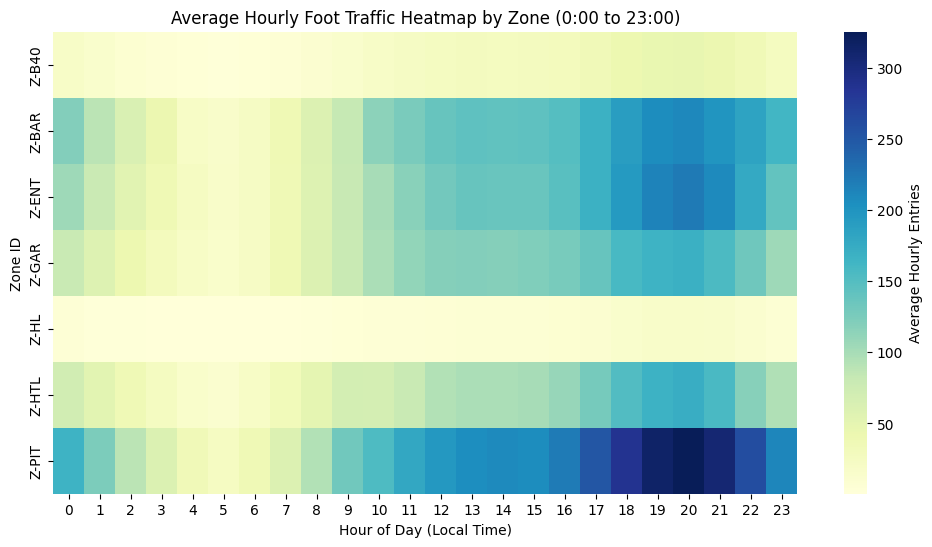

In [27]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load hourly zone traffic
traffic = pd.read_parquet("data/4_context/zone_traffic_hourly.parquet")

# Filter for operational counters ('ok') as specified in the guide
valid_traffic = traffic[traffic['counter_status'] == 'ok'].copy()

# 1. Total traffic by zone over the entire 6 months
zone_totals = valid_traffic.groupby('zone_id')['entries_count'].sum().reset_index().sort_values(by='entries_count', ascending=False)
print("--- Total Observed Foot Traffic by Zone ---")
print(zone_totals.to_string(index=False))

# 2. Hourly Foot Traffic Heatmap (Zone ID vs. Hour of Day)
traffic_pivot = valid_traffic.groupby(['zone_id', 'local_hour'])['entries_count'].mean().unstack()

plt.figure(figsize=(12, 6))
sns.heatmap(traffic_pivot, cmap='YlGnBu', annot=False, fmt=".0f", cbar_kws={'label': 'Average Hourly Entries'})
plt.title('Average Hourly Foot Traffic Heatmap by Zone (0:00 to 23:00)')
plt.xlabel('Hour of Day (Local Time)')
plt.ylabel('Zone ID')
plt.show()

In [28]:
# Load machine daily view
daily = pd.read_parquet("data/1_prepared_views/prepared_daily_view.parquet")

# Convert Decimal columns to float to prevent type errors during division
if 'coin_in_usd' in daily.columns:
    daily['coin_in_usd'] = daily['coin_in_usd'].astype(float)
if 'house_win_usd' in daily.columns:
    daily['house_win_usd'] = daily['house_win_usd'].astype(float)

# Aggregate financial performance per zone
zone_perf = daily.groupby('zone_id').agg(
    total_coin_in=('coin_in_usd', 'sum'),
    total_house_win=('house_win_usd', 'sum'),
    active_machine_days=('active', 'sum')
).reset_index()

# Merge with valid foot traffic entries
valid_traffic['gaming_date'] = pd.to_datetime(valid_traffic['hour_start_local']).dt.date
zone_traffic_daily = valid_traffic.groupby(['zone_id', 'gaming_date'])['entries_count'].sum().groupby('zone_id').sum().reset_index()

zone_summary = pd.merge(zone_perf, zone_traffic_daily, on='zone_id')

# Calculate Yield per Foot Traffic Entry
zone_summary['coin_in_per_entry'] = zone_summary['total_coin_in'] / zone_summary['entries_count']
zone_summary['house_win_per_entry'] = zone_summary['total_house_win'] / zone_summary['entries_count']

print("--- Zone Efficiency (Revenue per Foot Traffic Entry) ---")
print(zone_summary.sort_values(by='coin_in_per_entry', ascending=False).to_string(index=False))

--- Zone Efficiency (Revenue per Foot Traffic Entry) ---
zone_id  total_coin_in  total_house_win  active_machine_days  entries_count  coin_in_per_entry  house_win_per_entry
   Z-HL    17525210.00       1837089.00                 4344        29002.0         604.275912            63.343528
  Z-B40    24995974.35       2333674.20                 8541        97544.0         256.253325            23.924323
  Z-PIT    72180407.40       6847002.90                13803       746621.0          96.676101             9.170654
  Z-HTL    30185700.05       2843211.20                 6481       363496.0          83.042730             7.821850
  Z-BAR    39621934.60       3688067.95                 8744       507084.0          78.136827             7.273091
  Z-ENT    36493881.10       3446695.25                 6663       493403.0          73.963638             6.985558
  Z-GAR    27902111.75       2642414.60                 6516       411777.0          67.760248             6.417101


In [29]:
# Load real LVCVA monthly visitation benchmark data
city_visitation = pd.read_parquet("data/4_context/real_sources/city_visitation_monthly.parquet")

# Let's see the columns available in the dataset to make sure we select correctly
print("Available columns in city_visitation:", city_visitation.columns.tolist())

# Map correct column names for visitor counts
visitor_col = 'visitor_volume' if 'visitor_volume' in city_visitation.columns else 'visitor_count'
occupancy_col = 'occupancy_rate_pct' if 'occupancy_rate_pct' in city_visitation.columns else 'occupancy_pct'

columns_to_print = ['month', visitor_col, 'convention_attendance', occupancy_col]
valid_print_cols = [col for col in columns_to_print if col in city_visitation.columns]

print("\n--- LVCVA Las Vegas Tourism Benchmarks ---")
print(city_visitation[valid_print_cols])

# Compare monthly Gilded Ace Coin-In growth vs. Las Vegas Visitor Count growth
property_day['month'] = property_day['gaming_date'].dt.strftime('%Y-%m')
monthly_casino = property_day.groupby('month')['coin_in_usd'].sum().reset_index()

monthly_comparison = pd.merge(monthly_casino, city_visitation, on='month', how='inner')
print("\n--- Casino Monthly Coin-In vs. City Visitor Counts ---")
comparison_cols = ['month', 'coin_in_usd'] + [col for col in [visitor_col, occupancy_col] if col in monthly_comparison.columns]
print(monthly_comparison[comparison_cols].to_string(index=False))

Available columns in city_visitation: ['month', 'geography', 'days_in_month', 'visitor_volume', 'mean_visitors_per_calendar_day', 'visitor_yoy_ratio', 'convention_attendance', 'hotel_occupancy_ratio', 'airport_en_deplaned_passengers', 'source_revision', 'source_url', 'source_id', 'source_sha256', 'source_cells', 'as_of_limitation']

--- LVCVA Las Vegas Tourism Benchmarks ---
     month  visitor_volume  convention_attendance
0  2025-01         3341800                 628800
1  2025-02         2973300                 615400
2  2025-03         3386800                 533900
3  2025-04         3335900                 573600
4  2025-05         3418700                 511200
5  2025-06         3094800                 374600

--- Casino Monthly Coin-In vs. City Visitor Counts ---
  month coin_in_usd  visitor_volume
2025-01 41676918.15         3341800
2025-02 39577371.95         2973300
2025-03 43647425.45         3386800
2025-04 41288570.55         3335900
2025-05 42984383.30         3418700


=== 1. REVENUE LIFT BY EVENT ===
                                  event_name     coin_in_usd  house_win_usd comp_cost_usd coin_in_lift_vs_baseline
                      Super Bowl LIX weekend      1943776.35  192316.983333   1447.166667            605174.304392
           Gilded Ace Winter Slot Tournament  1861313.716667  182336.466667        1421.1            522711.671059
              EDC Las Vegas festival weekend  1826487.583333       167882.3   1402.366667            487885.537725
College basketball tournament opening rounds    1790927.0125    169339.2625        1338.7            452324.966892
         Gilded Ace Locals Appreciation Week  1402894.871429  133891.614286   1226.114286              64292.82582
                                    NAB Show       1385799.2      129487.22       1008.72             47197.154392
                         Baseline (No Event)  1338602.045608   127141.94223   1027.183108                      0.0
                                         CES   

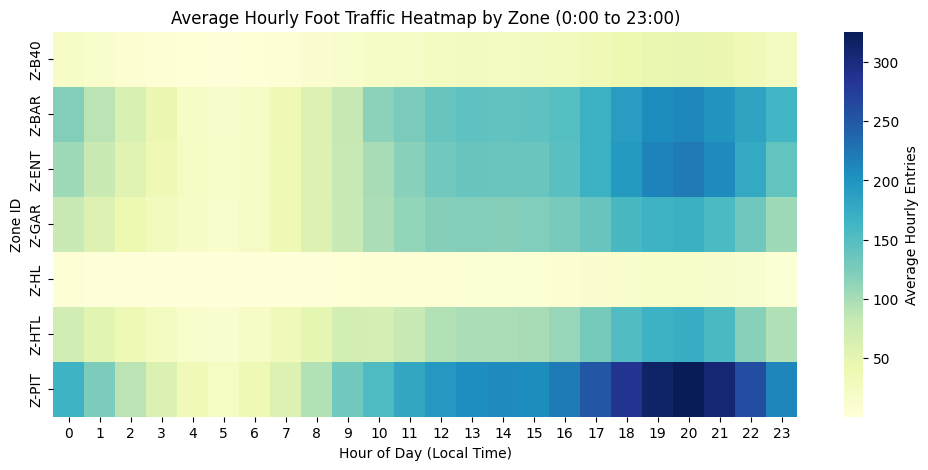

=== 3. ZONE EFFICIENCY (REVENUE PER ENTRY) ===
zone_id  total_coin_in  total_house_win  active_machine_days  entries_count  coin_in_per_entry  house_win_per_entry
   Z-HL    17525210.00       1837089.00                 4344        29002.0         604.275912            63.343528
  Z-B40    24995974.35       2333674.20                 8541        97544.0         256.253325            23.924323
  Z-PIT    72180407.40       6847002.90                13803       746621.0          96.676101             9.170654
  Z-HTL    30185700.05       2843211.20                 6481       363496.0          83.042730             7.821850
  Z-BAR    39621934.60       3688067.95                 8744       507084.0          78.136827             7.273091
  Z-ENT    36493881.10       3446695.25                 6663       493403.0          73.963638             6.985558
  Z-GAR    27902111.75       2642414.60                 6516       411777.0          67.760248             6.417101


=== 4. SVD VARIANCE EXP

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import StandardScaler

# ---------------------------------------------------------
# 1. EVENT LIFT ANALYSIS
# ---------------------------------------------------------
property_day = pd.read_parquet("data/1_prepared_views/property_day.parquet")
events = pd.read_parquet("data/4_context/events.parquet")

property_day['gaming_date'] = pd.to_datetime(property_day['gaming_date'])
events['start_date'] = pd.to_datetime(events['start_date'])
events['end_date'] = pd.to_datetime(events['end_date'])

# Map events to dates
date_event_map = {}
for _, row in events.iterrows():
    for dt in pd.date_range(start=row['start_date'], end=row['end_date']):
        date_event_map.setdefault(dt, []).append(row['name'])

property_day['active_events'] = property_day['gaming_date'].map(date_event_map)
property_day['has_event'] = property_day['active_events'].apply(lambda x: isinstance(x, list) and len(x) > 0)
property_day['event_name'] = property_day['active_events'].apply(lambda x: ", ".join(x) if isinstance(x, list) else "Baseline (No Event)")

event_impact = property_day.groupby('event_name')[['coin_in_usd', 'house_win_usd', 'comp_cost_usd']].mean().reset_index()
baseline_coin_in = property_day[~property_day['has_event']]['coin_in_usd'].mean()
event_impact['coin_in_lift_vs_baseline'] = event_impact['coin_in_usd'] - baseline_coin_in

print("=== 1. REVENUE LIFT BY EVENT ===")
print(event_impact.sort_values(by='coin_in_usd', ascending=False).to_string(index=False))
print("\n" + "="*50 + "\n")


# ---------------------------------------------------------
# 2. ZONE FOOT TRAFFIC & HEATMAP
# ---------------------------------------------------------
traffic = pd.read_parquet("data/4_context/zone_traffic_hourly.parquet")
valid_traffic = traffic[traffic['counter_status'] == 'ok'].copy()

zone_totals = valid_traffic.groupby('zone_id')['entries_count'].sum().reset_index().sort_values(by='entries_count', ascending=False)
print("=== 2. TOTAL OBSERVED FOOT TRAFFIC BY ZONE ===")
print(zone_totals.to_string(index=False))
print("\n" + "="*50 + "\n")

# Heatmap
traffic_pivot = valid_traffic.groupby(['zone_id', 'local_hour'])['entries_count'].mean().unstack()
plt.figure(figsize=(12, 5))
sns.heatmap(traffic_pivot, cmap='YlGnBu', annot=False, fmt=".0f", cbar_kws={'label': 'Average Hourly Entries'})
plt.title('Average Hourly Foot Traffic Heatmap by Zone (0:00 to 23:00)')
plt.xlabel('Hour of Day (Local Time)')
plt.ylabel('Zone ID')
plt.show()


# ---------------------------------------------------------
# 3. ZONE CONVERSION EFFICIENCY
# ---------------------------------------------------------
daily = pd.read_parquet("data/1_prepared_views/prepared_daily_view.parquet")
daily['coin_in_usd'] = daily['coin_in_usd'].astype(float)
daily['house_win_usd'] = daily['house_win_usd'].astype(float)

zone_perf = daily.groupby('zone_id').agg(
    total_coin_in=('coin_in_usd', 'sum'),
    total_house_win=('house_win_usd', 'sum'),
    active_machine_days=('active', 'sum')
).reset_index()

valid_traffic['gaming_date'] = pd.to_datetime(valid_traffic['hour_start_local']).dt.date
zone_traffic_daily = valid_traffic.groupby(['zone_id', 'gaming_date'])['entries_count'].sum().groupby('zone_id').sum().reset_index()

zone_summary = pd.merge(zone_perf, zone_traffic_daily, on='zone_id')
zone_summary['coin_in_per_entry'] = zone_summary['total_coin_in'] / zone_summary['entries_count']
zone_summary['house_win_per_entry'] = zone_summary['total_house_win'] / zone_summary['entries_count']

print("=== 3. ZONE EFFICIENCY (REVENUE PER ENTRY) ===")
print(zone_summary.sort_values(by='coin_in_per_entry', ascending=False).to_string(index=False))
print("\n" + "="*50 + "\n")


# ---------------------------------------------------------
# 4. SVD ANALYSIS ON PROPERTY DATA
# ---------------------------------------------------------
candidate_features = ['coin_in_usd', 'payout_usd', 'house_win_usd', 'theo_usd', 'active_machines', 'comp_cost_usd']
df_svd_clean = property_day[candidate_features].dropna()

for col in candidate_features:
    df_svd_clean[col] = df_svd_clean[col].astype(float)

X = df_svd_clean.drop(columns=['coin_in_usd'])
y = df_svd_clean['coin_in_usd']

X_scaled = StandardScaler().fit_transform(X)

svd = TruncatedSVD(n_components=2, random_state=42)
X_svd = svd.fit_transform(X_scaled)

loadings = pd.DataFrame(
    svd.components_.T,
    index=X.columns,
    columns=['SVD_Component_1 (Activity)', 'SVD_Component_2 (Capacity)']
)

svd_corr = pd.DataFrame(X_svd, columns=['SVD_Component_1', 'SVD_Component_2'])
svd_corr['coin_in_usd'] = y.values

print("=== 4. SVD VARIANCE EXPLAINED ===")
print(f"Component 1 Variance Explained: {svd.explained_variance_ratio_[0]:.2%}")
print(f"Component 2 Variance Explained: {svd.explained_variance_ratio_[1]:.2%}")
print(f"Total Top-2 Variance Explained: {svd.explained_variance_ratio_.sum():.2%}")

print("\n--- SVD Feature Loadings ---")
print(loadings.to_string())

print("\n--- Correlation of SVD Components to Daily Coin-In ---")
print(svd_corr.corr()['coin_in_usd'].to_string())

Event Impact: Super Bowl LIX weekend produced the highest coin-in lift (+$605,174 over standard baseline days), followed by the Winter Slot Tournament (+$522,712) and EDC Las Vegas (+$487,885).

Zone Traffic Efficiency: While Z-PIT received the highest total foot traffic ($746,621$ entries), Z-HL (High Limit) generated by far the highest yield per entry ($604.28 coin-in per entry vs. $96.68 in Z-PIT).

SVD Dimensionality: Component 1 (Activity Level) explains 73.6% of property-wide variance and correlates almost perfectly ($r = 0.99$) with daily coin_in_usd. Component 2 (Machine Capacity) explains 20.8% of variance but carries zero correlation ($r = -0.04$) to total casino wagers.

Sports & Gaming Promotions Drive High Gaming Spend: Sports viewing weekends and internal slot tournaments attract active gamblers who generate heavy wagers and higher comp costs (~$1,400+/day).

Conventions Do Not Equal Casino Floor Spend: Major tech/entertainment conventions like CES and CinemaCon bring large crowds to Las Vegas, but those attendees spend their time in convention halls—resulting in below-average gaming wagers at The Gilded Ace.

Zone Foot Traffic: Main entrance, pit, and bar areas experience massive foot traffic because they act as primary walkways and entry hubs for guests.

Zone Conversion Efficiency: Foot traffic volume does not equal revenue density. Thousands of guests walk past machines near entrances and garages without placing bets. Conversely, the High-Limit zone (Z-HL) receives very few entries, but each guest visiting that zone wagers significantly higher amounts. Optimization Opportunity: High-traffic zones (Z-ENT, Z-GAR) present prime locations for re-aligning machine mix or signage to convert casual passersby into active players.

Floor Demand is Single-Dimensional: Total daily casino wagers are driven almost entirely by SVD Component 1 (Floor Activity / Spend Level). When guest foot traffic, weekend crowds, and loyalty spend rise, coin-in rises proportionally.

Machine Count Does Not Drive Revenue: Minor daily shifts in machine availability (SVD Component 2) account for 20.8% of structural floor variation, but have zero impact on total daily wagers.